-   1.1开场串联&昨日复盘
    -   1.昨天（10/31）学了什么？今天和它是什么关系？
        -   昨天学习了卷积（3*3的核kernel），在图像上从左到右、从上到下扫，每处逐格相乘再相加，得到一个输出；还学了通道，参数共享，ReLU,两个信号叠加。
        -   今天学习stride和padding和另一类缩小尺寸的池化，将它们拼接成一张完整的小CNN逐层尺寸表，昨天是单个卷积，今天连成网络
    -   2.今天这块在整条项目链的那个位置？
        -   数据→张量→卷积特征→（今天的stride/padding/池化改变尺寸）→Flatten→Linear→10类分数
    -   3.今天学完，我能多做哪一件具体的事？ 
        -   不看讲义，能写出小 CNN 每一层的尺寸变化，说清 28→14→7 是怎么来的、Flatten 后那个 784 为什么是「16 通道×7×7」而不是「28×28」。

-   1.2复盘
    -  1. 4×4 图过 3×3 核，stride=1、padding=0，输出多大？为什么？
       -  输出边长=(输入边长-核边长)/stride+1=2 输出2*2
    -  2.Conv2d(1,8,3) 参数量多少？怎么算的？
       -  输出通道=8，输入=1，形状3*3   参数量=8*1*3*3+8=80
    -  3.卷积和残差是一回事吗？
       -  卷积是：局部加权计算；残差=将分支输出与输入相加x+x(r)，分支内部可以含卷积
    -  4.Conv2d(in,out,k)  weight.shape(out,in,k,k)


-   2.1stride
    -   1.一维公式：输出长度=floor((输入长度-核长度)/stride)+1
        -   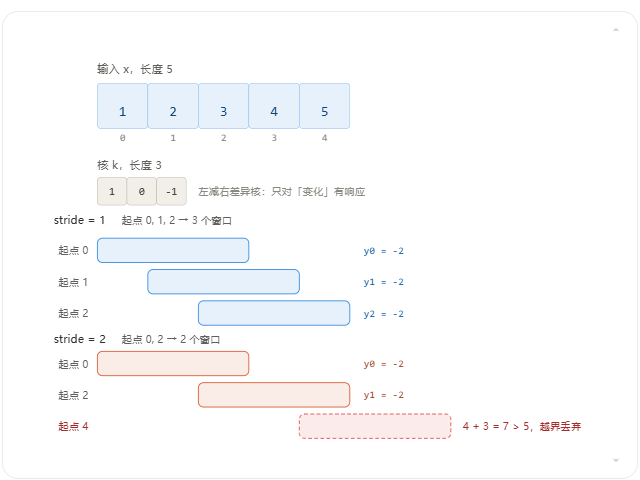
    -   2.二维公式：
        -   高和宽各算一次(padding=0)
    -   3.测试题：28×28、5×5 核、stride=2、padding=0，输出多大？
        -   floor((28-5)/2)+1=12  输出12*12
  

-   2.2 padding：给边缘垫一圈0
    -   stride=0,padding=0时，28*28过3*3后变成26*26，每过一层卷积小2，叠几层图就缩没了。padding就是补0，让尺寸不变或者可控
    -   比如4*4，padding=1→6*6 out=6-3+1=4 输出还是4*4这样子就不会变
    -   奇数核卷积后不变需要的padding是(kernel-1)/2
    -   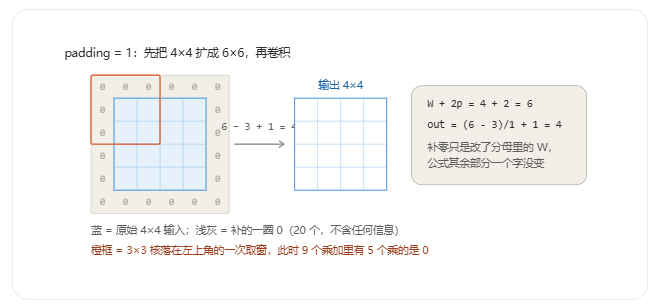

-   2.3 池化：把每一个方块压长一个数
    -   Maxpool2d（2）:将每个2*2取最大值，窗口默认stride=2(不重叠)，输出尺寸直接减半，AvgPool2d(2)取平均
        -   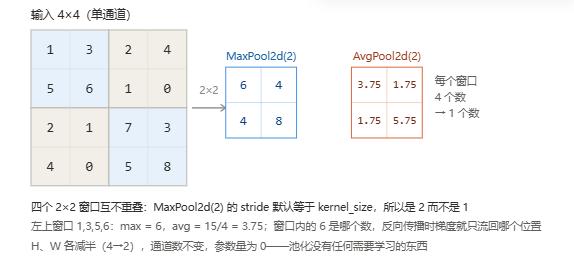
        -   池化和卷积用一套机制，输出=(输入-核)/stride+1
            -   28×28 过 MaxPool2d(2)，输出多大？
                -   (28-2)/2+1=14 输出14*14

In [ ]:
import torch
from torch import nn

x1 = torch.tensor([1., 2., 3., 4., 5.]).unsqueeze(0).unsqueeze(0)  # [1,1,5]
k1 = torch.tensor([1., 0., -1.]).unsqueeze(0).unsqueeze(0)         # [1,1,3]
for s in (1, 2):
    c = nn.Conv1d(1, 1, kernel_size=3, stride=s, bias=False)
    with torch.no_grad():
        c.weight.copy_(k1)
        y = c(x1)
    print(f'stride={s} 输入{x1.shape} 输出{y.shape} 值{y[0,0]}')


    #stride=1 输入torch.Size([1,1,5]) 输出torch.Size([1,1,3]) 值tensor([-2.,-2.,-2.])
    #stride=2 输入torch.Size([1,1,5]) 输出torch.Size([1,1,2]) 值tensor([-2.,-2])

stride=1 输入torch.Size([1, 1, 5]) 输出torch.Size([1, 1, 3]) 值tensor([-2., -2., -2.])
stride=2 输入torch.Size([1, 1, 5]) 输出torch.Size([1, 1, 2]) 值tensor([-2., -2.])


In [7]:
image = torch.tensor([
    [1., 2., 0., 1.],
    [0., 1., 3., 2.],
    [2., 1., 0., 0.],
    [1., 0., 2., 1.],
])
kernel = torch.tensor([
    [1., 0., -1.],
    [1., 0., -1.],
    [1., 0., -1.],
])
x = image.unsqueeze(0).unsqueeze(0)  # [1,1,4,4]

for p in (0, 1):
    c = nn.Conv2d(1, 1, kernel_size=3, padding=p, bias=False)
    with torch.no_grad():
        c.weight.copy_(kernel.unsqueeze(0).unsqueeze(0))
        y = c(x)
    print(f'padding={p} 输入{x.shape} 输出{y.shape}')
    print(y[0, 0])

    #x[1,1,4,4] c[1,1,3,3]
    # padding=0 输入torch.Size[1,1,4,4] 输出torch.Size[1,1,2,2]
    # tensor([[0.,1.],[-2.,-1.]])

    #padding=1 输入torch.Size[1,1,4,4] 输出torch.Size[1,1,4,4]

pool_max = nn.MaxPool2d(2)
pool_avg = nn.AvgPool2d(2)
print('MaxPool 输出：', pool_max(x))
print('AvgPool 输出：', pool_avg(x))


padding=0 输入torch.Size([1, 1, 4, 4]) 输出torch.Size([1, 1, 2, 2])
tensor([[ 0.,  1.],
        [-2., -1.]])
padding=1 输入torch.Size([1, 1, 4, 4]) 输出torch.Size([1, 1, 4, 4])
tensor([[-3., -2.,  0.,  3.],
        [-4.,  0.,  1.,  3.],
        [-2., -2., -1.,  5.],
        [-1.,  1.,  0.,  2.]])
MaxPool 输出： tensor([[[[2., 3.],
          [2., 2.]]]])
AvgPool 输出： tensor([[[[1.0000, 1.5000],
          [1.0000, 0.7500]]]])


In [ ]:
# 2.5拼写一个小CNN，逐层写shape
    # 输入                         [1,  1, 28, 28]    1 样本，1 通道，28×28
    # Conv2d(1,8,3, padding=1)   → [1,  8, 28, 28]   8 通道，尺寸不变
    # ReLU                        → [1,  8, 28, 28]   逐元素 max(0,x)，不改 shape
    # MaxPool2d(2)                → [1,  8, 14, 14]   尺寸减半
    # Conv2d(8,16,3, padding=1)  → [1, 16, 14, 14]   16 通道，尺寸不变
    # ReLU                        → [1, 16, 14, 14]
    # MaxPool2d(2)                → [1, 16,  7,  7]   尺寸再减半
    # Flatten                     → [1, 784]          16×7×7 = 784
    # Linear(784,10)              → [1,  10]          10 个类别分数

import torch
from torch import nn

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features=nn.Sequential(
            nn.Conv2d(1,8,kernel_size=3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(8,16,kernel_size=3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier=nn.Sequential(
            nn.Flatten(),
            nn.Linear(16*7*7,10),
        )

    def forward(self,x):
            x=self.features(x)
            return self.classifier(x)

model=SmallCNN()
x=torch.zeros(1,1,28,28)
with torch.no_grad():
    y=model(x)

print('输入：', x.shape)
print('输出：', y.shape)                # 预期 [1, 10]
print('参数量：', sum(p.numel() for p in model.parameters()))  # 预期 9098

#输入: torch.Size([1,1,28,28])
#输出: torch.Size([1,10])
#参数量: nn.Conv2d(1,8,kernel_size=3,padding=1):1*8*9+8=80  nn.Conv2d(8,16,kernel_size=3,padding=1):8*16*9+16=1168
# nn.Linear(16*7*7,10):16*7*7*10+10=7850
#7850+80+1168=9098

输入： torch.Size([1, 1, 28, 28])
输出： torch.Size([1, 10])
参数量： 9098


-   把输入改成 torch.zeros(2,1,28,28)，输出 shape 和参数量变吗？
    -   输出shape torch.Size([2,10]);参数不会变，batch只会影响每一个tensor的第0维，不会影响权重
-   想要 3×3 卷积后尺寸不变，padding 填几？
    -   奇数核要想卷积后尺寸不变，(kernel-1)/2=1=padding
-   池化会改变通道数吗？有可学习权重吗？
    -   池化不改变通道数，只改变尺寸，H和W；没有权重

In [10]:
def out_size(W, K, P=0, S=1):
    return (W + 2*P - K) // S + 1

for W, K, P, S in [(28,3,1,1), (28,3,0,2), (28,5,0,2), (7,3,1,1)]:
    c = nn.Conv2d(1, 1, kernel_size=K, padding=P, stride=S, bias=False)
    with torch.no_grad():
        y = c(torch.zeros(1, 1, W, W))
    print(f'W={W} K={K} P={P} S={S}: 公式={out_size(W,K,P,S)} 实际={y.shape[-1]}')

W=28 K=3 P=1 S=1: 公式=28 实际=28
W=28 K=3 P=0 S=2: 公式=13 实际=13
W=28 K=5 P=0 S=2: 公式=12 实际=12
W=7 K=3 P=1 S=1: 公式=7 实际=7


In [11]:
def show_shapes(model, x):
    hs, handles = [], []
    for name, m in model.named_modules():
        if isinstance(m, (nn.Conv2d, nn.MaxPool2d, nn.Flatten, nn.Linear)):
            handles.append(m.register_forward_hook(
                lambda m, i, o, name=name: hs.append((name, tuple(o.shape)))))
    with torch.no_grad():
        model(x)
    for h in handles: h.remove()
    for name, shape in hs:
        print(f'{name:40s} {shape}')

show_shapes(SmallCNN(), torch.zeros(1, 1, 28, 28))

features.0                               (1, 8, 28, 28)
features.2                               (1, 8, 14, 14)
features.3                               (1, 16, 14, 14)
features.5                               (1, 16, 7, 7)
classifier.0                             (1, 784)
classifier.1                             (1, 10)


-   验收
    -   你能不看讲义写出 out_size 公式并解释每个字母吗？
        -   out_size(W, K, P=0, S=1) W输入边长 K核边长 P padding是否补边 S stride步长
    -   show_shapes 打印出来是不是和手写 shape 表一致？
        -   一致

-   ---------------------------------------------------------------------------------------

-   3.1 FFT是干什么的
    -   FFT快速傅里叶变换，将时间-数值表变成频率-幅值表，是DFT离散傅里叶变换的高效算法
    -   时域看「某个时刻信号是多少」，频域看「每个频率成分有多强」。 横轴从「秒」换成「赫兹」

e:\develop\Graduate_AI\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 30456 (\N{CJK UNIFIED IDEOGRAPH-76F8}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
e:\develop\Graduate_AI\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 23545 (\N{CJK UNIFIED IDEOGRAPH-5BF9}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
e:\develop\Graduate_AI\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 22823 (\N{CJK UNIFIED IDEOGRAPH-5927}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
e:\develop\Graduate_AI\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 23567 (\N{CJK UNIFIED IDEOGRAPH-5C0F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
e:\develop\Graduate_AI\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 20449 (\N{CJK UNIFIED IDEOGRAPH-4FE1}) missing fro

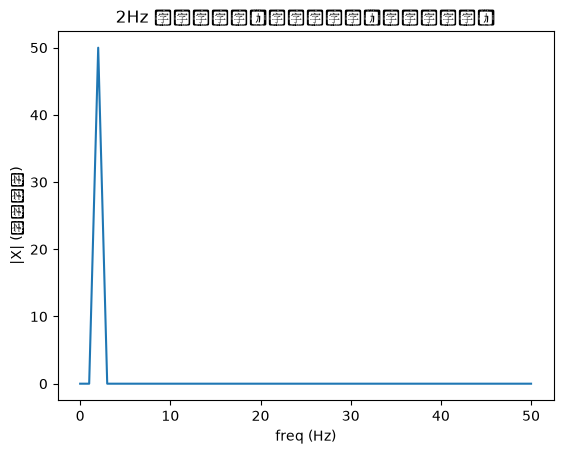

峰所在频率： 2.0 Hz


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

fs = 100            # 采样率：每秒采 100 个点
f0 = 2              # 信号频率 2 Hz
T = 1.0             # 观察 1 秒
N = int(fs * T)     # 100 个点
t = np.arange(N) / fs              #  时间轴0, 0.01, ..., 0.99
x = np.sin(2 * np.pi * f0 * t)     # 2Hz，1 秒 = 2 个整周期

X = np.fft.rfft(x)                       # 复数结果，长度 N//2+1 = 51  ffft(x)是对实数信号做傅里叶变换，返回非负频率的一半
freqs = np.fft.rfftfreq(N, d=1/fs)       # 频率轴：0,1,...,50 Hz
mag = np.abs(X)                          # 先看「相对大小」

plt.plot(freqs, mag)
plt.xlabel('freq (Hz)')
plt.ylabel('|X| (相对大小)')
plt.title('2Hz 信号的频谱（先看峰在哪，不纠结数值）')
plt.show()

# 峰在哪一格：
peak = int(np.argmax(mag))
print('峰所在频率：', freqs[peak], 'Hz')   # 预期 2.0

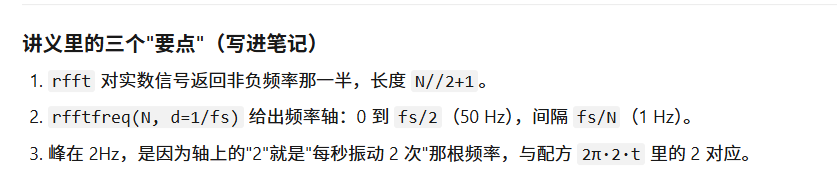

-   3.3 10.31预测
    -   2Hz + 0.5·5Hz  两个峰在2HZ 和5Hz fs/N=100/200=0.5Hz 间隔

f=2.5 Hz  amp=0.00
f=5.0 Hz  amp=0.50
f=2.0 Hz  amp=1.00


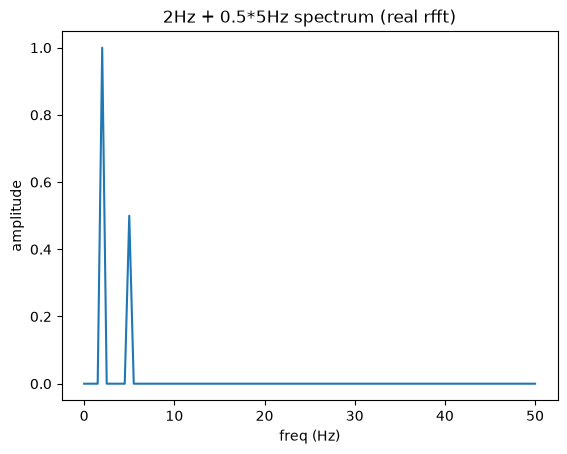

In [13]:
fs, T = 100, 2.0
t = np.arange(0, T, 1/fs)
s = np.sin(2*np.pi*2*t) + 0.5*np.sin(2*np.pi*5*t)

X2 = np.fft.rfft(s) #s是那串信号，x2是每个频率有多强
f2 = np.fft.rfftfreq(len(s), d=1/fs) # 生成频率轴
amp2 = np.abs(X2) * 2 / len(s) #乘以2是只留了rfft只留了正频率的一半，除以len(s)是因为fft是将n个点累加起来的结果

for i in np.argsort(amp2)[-3:]:
    print(f'f={f2[i]:.1f} Hz  amp={amp2[i]:.2f}')

plt.plot(f2, amp2)
plt.xlabel('freq (Hz)'); plt.ylabel('amplitude')
plt.title('2Hz + 0.5*5Hz spectrum (real rfft)')
plt.show()

-   ---------------------------------------------------------------------------------------

-   4.论文
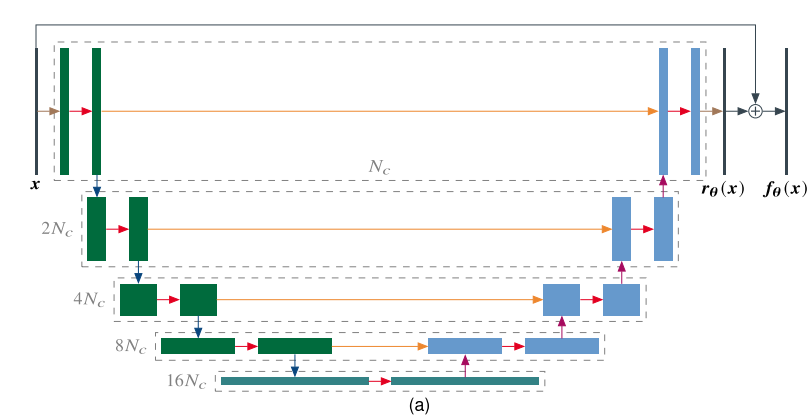

    -   下采样，通道变多，空间尺寸变小（reduce the spatial dimension while augmenting the channel number.）本文使用了stride，而不是最大池化（Instead of a max-pooling layer, which seems inadequate for restoration tasks, a 2 × 2 strided CL was used within each downsampling layer as a symmetric counterpart to the 2 × 2 strided “transposed” CL used within each upsampling layer.）   
    -   上采样，空间尺寸变大，回复细节（The channel number is contracted back to its initial state (rightmost chamoisee arrow)）
    -   同尺度连接，编码器与解码器同分辨率特征接起来	尺寸不变	本文说明内部连接用相加，不是拼接
    -   最终残差，网络输出=输入+分支改动

-   ---------------------------------------------------------------------------------------

-   标题：High Volume Rate 3D Ultrasound Reconstruction with Diffusion Models
    -   基于扩散模型的高容积率3维超声重建
-   Abstract：
    -   Three-dimensional ultrasound enables realtime volumetric visualization of anatomical structures. Unlike traditional 2D ultrasound, 3D imaging reduces reliance on precise probe orientation, potentially making ultrasound more accessible to clinicians with varying levels of experience and improving automated measurements and postexam analysis.
        -   三维超声使解剖结构的实时体积可视化成为可能。与传统的2D超声不同，3D成像减少了对精确探头定位的依赖，潜在地使具有不同经验水平的临床医生更容易接触到超声，并改进了自动化测量和检查后分析。
    -   However, achieving both high volume rates and high image quality remains a significant challenge.（引出问题）
        -   然而，同时实现高容积率和高图像质量仍然是一个巨大的挑战。
    -   While 3D diverging waves can provide high volume rates, they suffer from limited tissue harmonic generation and increased multipath effects, which degrade image quality.
        -   虽然3D发散波可以提供高容积率，但它们受到组织谐波产生有限和多径效应增加的影响，这会降低图像质量。
    -   One compromise is to retain focus in elevation while leveraging unfocused diverging waves in the lateral direction to reduce the number of transmissions per elevation plane.
        -   一种折衷方案是在保持高程聚焦的同时，利用横向的非聚焦发散波来减少每个高程平面的传输次数。
    -   Reaching the volume rates achieved by full 3D diverging waves, however, requires dramatically undersampling the number of elevation planes.
        -   然而，要达到全3D发散波所达到的体积率，需要对高程平面的数量进行大幅不足的采样。
    -   Subsequently, to render the full volume, simple interpolation techniques are applied.
        -   随后，为了渲染整个体积，应用了简单的内插技术。
    -   This paper introduces a novel approach to 3D ultrasound reconstruction from a reduced set of elevation planes by employing diffusion models (DMs) to achieve increased spatial and temporal resolution.
        -   本文介绍了一种利用扩散模型(DM)从一组减少的仰面重建三维超声的新方法，以提高空间和时间分辨率。
    -   We compare both traditional and supervised deep learning-based interpolation methods on a 3D cardiac ultrasound dataset.
        -   我们在三维心脏超声数据集上比较了传统的和有监督的基于深度学习的内插方法。
    -   Our results show that DMbased reconstruction consistently outperforms the baselines in image quality and downstream task performance.
        -   我们的结果表明，基于DM的重建在图像质量和下游任务性能方面始终优于基线。
    -   Additionally, we accelerate inference by leveraging the temporal consistency inherent to ultrasound sequences.
        -   此外，我们通过利用超声序列固有的时间一致性来加速推理。
    -   Finally, we explore the robustness of the proposed method by exploiting the probabilistic nature of diffusion posterior sampling to quantify reconstruction uncertainty and demonstrate improved recall on out-of-distribution data with synthetic anomalies under strong subsampling.
        -   最后，我们利用扩散后验抽样的概率性质来量化重建不确定性，并证明了在强次抽样下对含有合成异常的离散型数据的召回率提高了方法的稳健性。
    -   Code is available at 3d-ultrasound-diffusion.github.io
        -   代码可在3D-超声波-Diffusion.gihub.io上获得
-   Conclusion
    -   3D ultrasound holds significant promise for the future of ultrasound imaging, particularly in cardiac applications.
        -   三维超声对超声成像的未来有着重要的前景，特别是在心脏应用方面。
    -   However, its clinical adoption remains limited due to constraints in temporal and spatial resolution, often leading clinicians to fall back to 2D imaging.
        -   然而，由于时间和空间分辨率的限制，它的临床应用仍然有限，经常导致临床医生退回到2D成像。
    -   To push this trade-off, one can employ spatial subsampling to reduce the number of transmit events, thereby enabling higher frame rates or broader coverage.
        -   为了实现这一权衡，可以使用空间子采样来减少传输事件的数量，从而实现更高的帧速率或更广的覆盖范围。
    -   Yet, conventional interpolation methods, as well as supervised learning-based approaches, struggle to fully reconstruct undersampled volumes, especially at high acceleration rates.
        -   然而，传统的插值法以及基于监督学习的方法很难完全重建欠采样的体积，特别是在高加速比下。
    -   In this work, we reframe 3D ultrasound reconstruction as a Bayesian inverse problem, leveraging deep generative priors to substantially improve reconstruction quality.
        -   在这项工作中，我们将三维超声重建重新定义为一个贝叶斯逆问题，利用深度生成先验来显著提高重建质量。
    -   Our approach demonstrates clear benefits not only in terms of visual fidelity but also in clinically relevant downstream tasks such as speckle tracking.
        -   我们的方法不仅在视觉保真度方面显示出明显的好处，而且在临床相关的下游任务中也显示出明显的好处，例如斑点跟踪。
    -   Moreover, by extending our diffusion-based interpolation framework to exploit the sequential nature of ultrasound data, we achieve both improved temporal consistency and significant acceleration, bringing the method closer to real-time applicability.
        -   此外，通过扩展我们的基于扩散的内插框架来利用超声数据的顺序性质，我们实现了改进的时间一致性和显著的加速，使该方法更接近实时适用性。
    -   Finally, the probabilistic nature of our model enables estimation of reconstruction uncertainty, offering a valuable tool for clinical decision-making and a foundation for future work on uncertainty-aware imaging and adaptive acquisition strategies
        -   最后，我们的模型的概率性质使得能够估计重建的不确定性，为临床决策提供了有价值的工具，并为未来不确定性感知成像和自适应采集策略的工作奠定了基础